In [1]:
!pip install -q pymupdf pikepdf datasets pillow pandas matplotlib transformers

In [2]:
# Libraries
from datasets import load_dataset
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
from PIL import Image
from IPython.display import display
import random
import torch
from transformers import pipeline
import io
import random
import pikepdf

In [3]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Getting data from DocLayNet
dataset = load_dataset(
    "docling-project/DocLayNet-v1.1"
)

print(dataset)

print(dataset["train"].column_names)

README.md:   0%|          | 0.00/6.38k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

data/train-00000-of-00029-8b4e0831de777e(…): reconstructing file:   0%|          |  0.00B / 1.13GB            

data/train-00000-of-00029-8b4e0831de777e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00029-d8ed8f026d2b91(…): reconstructing file:   0%|          |  0.00B / 1.12GB            

data/train-00001-of-00029-d8ed8f026d2b91(…): downloading bytes:           |  0.00B            

... (65 outputs left out)

Generating test split:   0%|          | 0/4999 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/6489 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/39 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata'],
        num_rows: 69375
    })
    test: Dataset({
        features: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata'],
        num_rows: 4999
    })
    val: Dataset({
        features: ['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata'],
        num_rows: 6489
    })
})
['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata']


In [5]:
# Looking at training samples
train_data = dataset["train"]

print("Training samples:", len(train_data))

# Inspect available categories
print(train_data[0].keys())

Training samples: 69375
dict_keys(['image', 'bboxes', 'category_id', 'segmentation', 'area', 'pdf_cells', 'metadata'])


In [6]:
# All categories
categories = {
    1: "Caption",
    2: "Footnote",
    3: "Formula",
    4: "List-item",
    5: "Page-footer",
    6: "Page-header",
    7: "Picture",
    8: "Section-header",
    9: "Table",
    10: "Text",
    11: "Title"
}

In [7]:
# Getting all pdfs that contain images
picture_pages = []

for i, sample in enumerate(train_data):

    category_ids = sample["category_id"]

    if 7 in category_ids:
        picture_pages.append(i)

print("Pages containing pictures:", len(picture_pages))

Pages containing pictures: 20493


In [8]:
# Pipeline to implement an image captioning model (BLIP)
captioner = pipeline(
    "image-to-text",
    model="Salesforce/blip-image-captioning-base",
    device=0 if torch.cuda.is_available() else -1
)

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

--- Logging error ---
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 1151, in emit
    msg = self.format(record)
  File "/usr/lib/python3.13/logging/__init__.py", line 999, in format
    return fmt.format(record)
           ~~~~~~~~~~^^^^^^^^
  File "/usr/lib/python3.13/logging/__init__.py", line 712, in format
    record.message = record.getMessage()
                     ~~~~~~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/logging/__init__.py", line 400, in getMessage
    msg = msg % self.args
          ~~~~^~~~~~~~~~~
TypeError: not all arguments converted during string formatting
Call stack:
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.sta

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

In [9]:
# Get images using DocLayNet's bounding boxes

def extract_figure_crops(sample):

    page_image = sample["image"].convert("RGB")

    image_width, image_height = page_image.size

    coco_width = sample["metadata"]["coco_width"]
    coco_height = sample["metadata"]["coco_height"]

    scale_x = image_width / coco_width
    scale_y = image_height / coco_height

    figure_crops = []

    for bbox, category in zip(
        sample["bboxes"],
        sample["category_id"]
    ):

        if category != 7:
            continue

        # COCO format: x, y, width, height
        x, y, w, h = map(float, bbox)

        left = round(x * scale_x)
        top = round(y * scale_y)

        right = round((x + w) * scale_x)
        bottom = round((y + h) * scale_y)

        # Keep coordinates within image boundaries
        left = max(0, min(left, image_width))
        right = max(0, min(right, image_width))

        top = max(0, min(top, image_height))
        bottom = max(0, min(bottom, image_height))

        if right <= left or bottom <= top:
            continue

        crop = page_image.crop((
            left,
            top,
            right,
            bottom
        ))

        figure_crops.append(crop)

    return figure_crops

Number of figures: 2


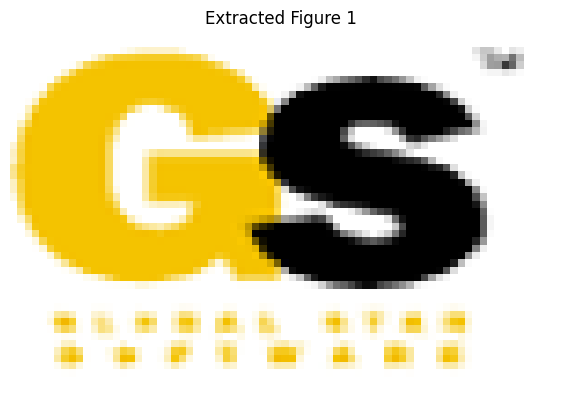

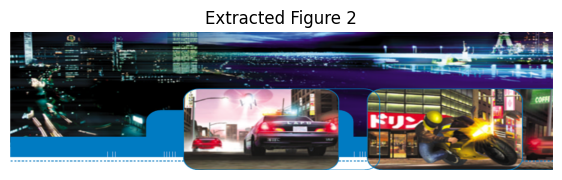

In [10]:
# Testing extraction

sample = train_data[picture_pages[0]]

figure_images = extract_figure_crops(sample)

print("Number of figures:", len(figure_images))

for i, img in enumerate(figure_images):

    plt.figure(figsize=(7, 5))
    plt.imshow(img)
    plt.title(f"Extracted Figure {i + 1}")
    plt.axis("off")
    plt.show()

In [11]:
# Initializing BLIP model for meaningful caption generation
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

model.eval()

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-11): 12 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (projection): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
    (post_layernorm): Laye

In [12]:
# Generating meaningful captions from BLIP
def generate_meaningful_captions(images):

    captions = []

    for image in images:

        inputs = processor(
            images=image.convert("RGB"),
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():

            output = model.generate(
                **inputs,
                max_new_tokens=100,
                num_beams=5
            )

        caption = processor.decode(
            output[0],
            skip_special_tokens=True
        )

        captions.append(caption)

    return captions

In [13]:
# Look at an example meaningful caption
sample = train_data[picture_pages[0]]

figure_images = extract_figure_crops(sample)

captions = generate_meaningful_captions(figure_images)

for i, caption in enumerate(captions):

    print(f"Figure {i + 1}: {caption}")

Figure 1: the g s logo
Figure 2: an image of a city at night


In [14]:
# Produce nonmeaningful captions

# ============================================================
# 300 NONMEANINGFUL ALT TEXT OPTIONS
# ============================================================

nonmeaningful_options = [

    # 1-30: Generic filenames
    "image.jpg",
    "image.png",
    "image.jpeg",
    "image.gif",
    "image.tif",
    "image.bmp",
    "picture.jpg",
    "picture.png",
    "photo.jpg",
    "photo.png",
    "graphic.jpg",
    "graphic.png",
    "figure.jpg",
    "figure.png",
    "diagram.jpg",
    "diagram.png",
    "chart.jpg",
    "chart.png",
    "illustration.jpg",
    "illustration.png",
    "scan001.jpg",
    "scan002.jpg",
    "img001.jpg",
    "img002.png",
    "img003.jpeg",
    "image001.jpg",
    "image002.png",
    "picture001.jpg",
    "photo001.png",
    "graphic001.jpg",

    # 31-60: Figure and image identifiers
    "figure1",
    "figure2",
    "figure3",
    "figure4",
    "figure5",
    "figure 1",
    "figure 2",
    "figure 3",
    "figure 4",
    "figure 5",
    "Figure 01",
    "Figure 02",
    "Figure 03",
    "Fig. 1",
    "Fig. 2",
    "Fig. 3",
    "Fig. 4",
    "Fig. 5",
    "fig1",
    "fig2",
    "fig3",
    "fig4",
    "fig5",
    "image 1",
    "image 2",
    "image 3",
    "image 4",
    "image 5",
    "picture 1",
    "picture 2",

    # 61-90: Generic object labels
    "image",
    "picture",
    "photo",
    "graphic",
    "figure",
    "chart",
    "diagram",
    "illustration",
    "visual",
    "drawing",
    "screenshot",
    "photograph",
    "artwork",
    "map",
    "table",
    "icon",
    "logo",
    "symbol",
    "object",
    "file",
    "media",
    "visual content",
    "graphic content",
    "image file",
    "picture file",
    "photo file",
    "figure file",
    "chart image",
    "diagram image",
    "visual element",

    # 91-120: Vague descriptions
    "An image",
    "A picture",
    "A photo",
    "A graphic",
    "A figure",
    "A chart",
    "A diagram",
    "An illustration",
    "A visual",
    "A drawing",
    "A screenshot",
    "A photograph",
    "An object",
    "A symbol",
    "A logo",
    "A map",
    "A table",
    "An icon",
    "Some graphics",
    "Some images",
    "Some pictures",
    "A visual representation",
    "An image is shown",
    "A picture is shown",
    "A graphic is displayed",
    "A figure is displayed",
    "A chart is displayed",
    "A diagram is displayed",
    "Visual representation",
    "Graphical representation",

    # 121-150: Decorative and uninformative descriptions
    "This image is decorative",
    "Decorative image",
    "Decorative graphic",
    "Decorative picture",
    "Decorative figure",
    "This is a decorative image",
    "This is a decorative graphic",
    "This picture is decorative",
    "This figure is decorative",
    "Decorative visual element",
    "No description available",
    "No image description",
    "No alternative text available",
    "No alt text",
    "Alt text unavailable",
    "Description unavailable",
    "Image description unavailable",
    "Not described",
    "No details provided",
    "No information available",
    "This image has no description",
    "This graphic has no description",
    "This picture has no description",
    "This figure has no description",
    "This image has no details",
    "No meaningful description",
    "Image without description",
    "Picture without description",
    "Graphic without description",
    "Figure without description",

    # 151-180: Placeholder text
    "TODO",
    "TBD",
    "N/A",
    "NA",
    "None",
    "Unknown",
    "Undefined",
    "Untitled",
    "Placeholder",
    "Placeholder image",
    "Placeholder graphic",
    "Placeholder figure",
    "Placeholder picture",
    "Replace image",
    "Replace this image",
    "Insert image here",
    "Insert picture here",
    "Image goes here",
    "Picture goes here",
    "Add image",
    "Add description",
    "Add alt text",
    "Enter description",
    "Description goes here",
    "Image description",
    "Alt text goes here",
    "Missing description",
    "Missing alt text",
    "To be described",
    "Not specified",

    # 181-210: Vague references
    "See image",
    "See figure",
    "See chart",
    "See diagram",
    "See picture",
    "Refer to image",
    "Refer to figure",
    "Refer to chart",
    "Refer to diagram",
    "As shown",
    "Shown below",
    "Shown above",
    "Shown here",
    "See below",
    "See above",
    "Refer below",
    "Refer above",
    "The following image",
    "The image below",
    "The image above",
    "The figure below",
    "The figure above",
    "The chart below",
    "The chart above",
    "The picture below",
    "The picture above",
    "Displayed below",
    "Displayed above",
    "Shown in the document",
    "See attached image",

    # 211-240: Uninformative statements
    "This is an image",
    "This is a picture",
    "This is a figure",
    "This is a chart",
    "This is a diagram",
    "This is a graphic",
    "This is a photograph",
    "This is an illustration",
    "There is an image",
    "There is a picture",
    "There is a figure",
    "There is a chart",
    "There is a diagram",
    "An image is present",
    "A picture is present",
    "A figure is present",
    "A chart is present",
    "A diagram is present",
    "An image appears",
    "A picture appears",
    "A graphic appears",
    "A figure appears",
    "A chart appears",
    "A diagram appears",
    "Image displayed",
    "Picture displayed",
    "Figure displayed",
    "Chart displayed",
    "Diagram displayed",
    "Graphic displayed",

    # 241-270: File and software references
    "Untitled.jpg",
    "Untitled.png",
    "New Image.jpg",
    "New Image.png",
    "Screenshot.jpg",
    "Screenshot.png",
    "Screenshot 1",
    "Screenshot 2",
    "Screenshot 3",
    "Document image",
    "PDF image",
    "Embedded image",
    "Imported image",
    "Attached image",
    "Uploaded image",
    "Scanned image",
    "Scanned picture",
    "Exported image",
    "Generated image",
    "Raster image",
    "Vector image",
    "Image object",
    "Graphic object",
    "Picture object",
    "Image placeholder",
    "Object 1",
    "Object 2",
    "Object 3",
    "Media object",
    "Unnamed graphic",

    # 271-300: Repetitive and generic phrases
    "A visual item",
    "A graphical item",
    "An image element",
    "A picture element",
    "A graphic element",
    "A figure element",
    "An embedded graphic",
    "An embedded picture",
    "An embedded figure",
    "An embedded photograph",
    "An image file is shown",
    "A picture file is shown",
    "A graphic file is shown",
    "A figure file is shown",
    "A visual file is shown",
    "The image is visible",
    "The picture is visible",
    "The graphic is visible",
    "The figure is visible",
    "The chart is visible",
    "The diagram is visible",
    "Some visual content",
    "Various visual elements",
    "Graphical content",
    "Image content",
    "Picture content",
    "Figure content",
    "Chart content",
    "Diagram content",
    "Visual content is present",

    # Missing or blank alternative text
    None,
    "",
    " ",
]


def generate_nonmeaningful_alt():

    return random.choice(nonmeaningful_options)

In [15]:
# Check if DocLayNet PDFs are tagged for alt text

def inspect_pdf_tags(pdf_path):

    with pikepdf.open(pdf_path) as pdf:

        root = pdf.Root

        if "/StructTreeRoot" not in root:
            return False

        return True

In [16]:
# Within structure tree, change alt text
def modify_figure_alt_text(pdf_path, output_path, alt_texts):

    with pikepdf.open(pdf_path) as pdf:

        if "/StructTreeRoot" not in pdf.Root:
            raise ValueError("PDF does not contain a structure tree.")

        struct_root = pdf.Root.StructTreeRoot

        figure_elements = []

        def find_figures(element):

            if isinstance(element, pikepdf.Array):

                for child in element:
                    find_figures(child)

            elif isinstance(element, pikepdf.Dictionary):

                if str(element.get("/S", "")) == "/Figure":
                    figure_elements.append(element)

                if "/K" in element:
                    find_figures(element["/K"])

        find_figures(struct_root["/K"])

        if len(figure_elements) != len(alt_texts):
            raise ValueError(
                f"Found {len(figure_elements)} figures, "
                f"but received {len(alt_texts)} descriptions."
            )

        for figure, alt_text in zip(figure_elements, alt_texts):

            figure["/Alt"] = pikepdf.String(alt_text)

        pdf.save(output_path)

    return output_path

In [17]:
# Generate balanced dataset
random.seed(42)

output_dir = "/content/drive/MyDrive/EEE6778_Semester_Project/generated_pdfs"

os.makedirs(output_dir, exist_ok=True)

records = []

def create_pdf_variants(
    pdf_path,
    meaningful_captions,
    sample_id
):

    # Meaningful version
    meaningful_path = os.path.join(
        output_dir,
        f"{sample_id}_meaningful.pdf"
    )

    modify_figure_alt_text(
        pdf_path,
        meaningful_path,
        meaningful_captions
    )

    records.append({
        "sample_id": sample_id,
        "pdf_path": meaningful_path,
        "alt_text_class": 1,
        "alt_text_type": "meaningful"
    })

    # Nonmeaningful version
    bad_captions = [
        generate_nonmeaningful_alt()
        for _ in meaningful_captions
    ]

    nonmeaningful_path = os.path.join(
        output_dir,
        f"{sample_id}_nonmeaningful.pdf"
    )

    modify_figure_alt_text(
        pdf_path,
        nonmeaningful_path,
        bad_captions
    )

    records.append({
        "sample_id": sample_id,
        "pdf_path": nonmeaningful_path,
        "alt_text_class": 0,
        "alt_text_type": "nonmeaningful"
    })

In [18]:
# Reproducibility
random.seed(42)

# Output directory
output_dir = "/content/drive/MyDrive/EEE6778_Semester_Project/doclaynet_synthetic_dataset"

image_dir = os.path.join(output_dir, "images")

os.makedirs(image_dir, exist_ok=True)

records = []

# Limit initial experiment
MAX_PAGES = 500

selected_pages = picture_pages[:MAX_PAGES]

for page_num, idx in enumerate(selected_pages):

    sample = train_data[idx]

    # Extract figure images
    figure_images = extract_figure_crops(sample)

    if len(figure_images) == 0:
        continue

    # Generate meaningful descriptions
    captions = generate_meaningful_captions(figure_images)

    # Original document identifier
    document_id = sample["metadata"]["original_filename"]

    for figure_id, (image, caption) in enumerate(
        zip(figure_images, captions)
    ):

        # Save figure image
        image_filename = (
            f"doc_{idx}_figure_{figure_id}.png"
        )

        image_path = os.path.join(
            image_dir,
            image_filename
        )

        image.save(image_path)

        # Meaningful sample
        records.append({
            "document_id": document_id,
            "page_id": idx,
            "figure_id": figure_id,
            "image_path": image_path,
            "alt_text": caption,
            "alt_text_class": 1,
            "alt_text_type": "meaningful",
            "dataset_source": "DocLayNet"
        })

        # Nonmeaningful sample
        records.append({
            "document_id": document_id,
            "page_id": idx,
            "figure_id": figure_id,
            "image_path": image_path,
            "alt_text": generate_nonmeaningful_alt(),
            "alt_text_class": 0,
            "alt_text_type": "nonmeaningful",
            "dataset_source": "DocLayNet"
        })

    if (page_num + 1) % 10 == 0:

        print(
            f"Processed {page_num + 1}/{len(selected_pages)} pages | "
            f"Generated samples: {len(records)}"
        )


# Create DataFrame
df = pd.DataFrame(records)

print("\nDataset generation complete!")

print("Total samples:", len(df))

print("\nClass distribution:")
print(df["alt_text_type"].value_counts())

Processed 10/500 pages | Generated samples: 30
Processed 20/500 pages | Generated samples: 60
Processed 30/500 pages | Generated samples: 94
Processed 40/500 pages | Generated samples: 122
Processed 50/500 pages | Generated samples: 148
Processed 60/500 pages | Generated samples: 214
Processed 70/500 pages | Generated samples: 252
Processed 80/500 pages | Generated samples: 286
Processed 90/500 pages | Generated samples: 316
Processed 100/500 pages | Generated samples: 364
Processed 110/500 pages | Generated samples: 390
Processed 120/500 pages | Generated samples: 422
Processed 130/500 pages | Generated samples: 470
Processed 140/500 pages | Generated samples: 510
Processed 150/500 pages | Generated samples: 546
Processed 160/500 pages | Generated samples: 574
Processed 170/500 pages | Generated samples: 604
Processed 180/500 pages | Generated samples: 642
Processed 190/500 pages | Generated samples: 674
Processed 200/500 pages | Generated samples: 720
Processed 210/500 pages | Genera

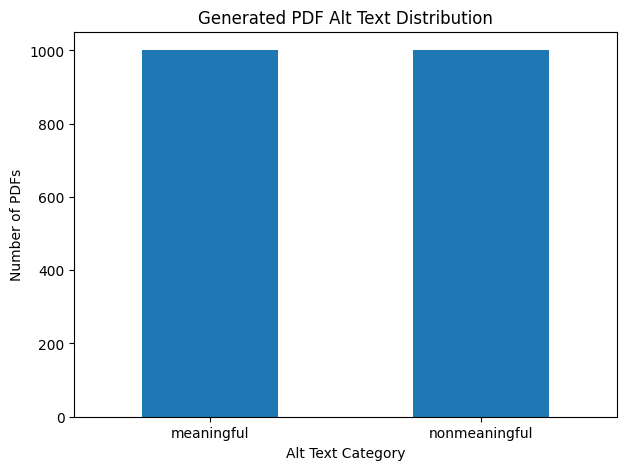

alt_text_type
meaningful       1001
nonmeaningful    1001
Name: count, dtype: int64


In [19]:
# Validate distribution
counts = df["alt_text_type"].value_counts()

plt.figure(figsize=(7, 5))

counts.plot(kind="bar")

plt.title("Generated PDF Alt Text Distribution")
plt.xlabel("Alt Text Category")
plt.ylabel("Number of PDFs")

plt.xticks(rotation=0)
plt.show()

print(counts)

In [20]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five samples:")

display(df.head())

print("\nClass distribution:")

display(
    df["alt_text_type"].value_counts().to_frame()
)

Dataset shape: (2002, 8)

Columns:
['document_id', 'page_id', 'figure_id', 'image_path', 'alt_text', 'alt_text_class', 'alt_text_type', 'dataset_source']

First five samples:


,document_id,page_id,figure_id,image_path,alt_text,alt_text_class,alt_text_type,dataset_source
0,NASDAQ_TTWO_2003.pdf,1,0,/content/drive/MyDrive/EEE6778_Semester_Projec...,the g s logo,1,meaningful,DocLayNet
1,NASDAQ_TTWO_2003.pdf,1,0,/content/drive/MyDrive/EEE6778_Semester_Projec...,image 5,0,nonmeaningful,DocLayNet
2,NASDAQ_TTWO_2003.pdf,1,1,/content/drive/MyDrive/EEE6778_Semester_Projec...,an image of a city at night,1,meaningful,DocLayNet
3,NASDAQ_TTWO_2003.pdf,1,1,/content/drive/MyDrive/EEE6778_Semester_Projec...,figure.jpg,0,nonmeaningful,DocLayNet
4,NYSE_ED_2003.pdf,3,0,/content/drive/MyDrive/EEE6778_Semester_Projec...,a group of people working on a construction site,1,meaningful,DocLayNet



Class distribution:


,count
alt_text_type,
meaningful,1001
nonmeaningful,1001


In [21]:
# Output directory in Google Drive
output_dir = "/content/drive/MyDrive/EEE6778_Semester_Project/doclaynet_synthetic_dataset"

os.makedirs(output_dir, exist_ok=True)

# Save dataset as CSV
csv_path = os.path.join(
    output_dir,
    "synthetic_alt_text_dataset.csv"
)

df.to_csv(csv_path, index=False)

# Save dataset as Excel
excel_path = os.path.join(
    output_dir,
    "synthetic_alt_text_dataset.xlsx"
)

df.to_excel(excel_path, index=False)

# Display confirmation
print("Dataset successfully saved to Google Drive!")

print("CSV:", csv_path)
print("Excel:", excel_path)

print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["alt_text_type"].value_counts())

Dataset successfully saved to Google Drive!
CSV: /content/drive/MyDrive/EEE6778_Semester_Project/doclaynet_synthetic_dataset/synthetic_alt_text_dataset.csv
Excel: /content/drive/MyDrive/EEE6778_Semester_Project/doclaynet_synthetic_dataset/synthetic_alt_text_dataset.xlsx

Dataset shape: (2002, 8)

Class distribution:
alt_text_type
meaningful       1001
nonmeaningful    1001
Name: count, dtype: int64
